In [2]:

import pandas as pd
from pathlib import Path

# Find the project folder
current = Path.cwd()

if current.name == "notebooks":
    project_path = current.parent
else:
    project_path = current

# Location of the collision dataset
file_path = project_path / "data" / "raw" / "dft-road-casualty-statistics-collision-2025.csv"

# Read the dataset
df = pd.read_csv(file_path, low_memory=False)

# Display dataset information
print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the first 5 rows
display(df.head())



ModuleNotFoundError: No module named 'pandas'

ModuleNotFoundError: No module named 'pandas'

In [1]:
import sys
print(sys.executable)


C:\Users\ECC\AppData\Local\Programs\Python\Python311\python.exe


In [2]:

import pandas as pd
from pathlib import Path

# Find the project folder
current = Path.cwd()
project_path = current.parent if current.name == "notebooks" else current

# Collision dataset location
file_path = project_path / "data" / "raw" / "dft-road-casualty-statistics-collision-2025.csv"

# Load the dataset
df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of rows: 101525
Number of columns: 44


,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202517M101925,2025,17M101925,447673.0,519279.0,-1.26420,54.56650,17,3,1,...,-1,0,1,1,2,E01012014,3,1,0.0,1.0
1,202517L205225,2025,17L205225,454611.0,518597.0,-1.15704,54.55967,17,3,2,...,-1,0,1,1,2,E01012173,3,1,0.0,1.0
2,2025070971700,2025,070971700,354476.0,382656.0,-2.68516,53.33884,7,3,2,...,-1,0,2,1,2,E01012444,3,1,0.0,1.0
3,2025070403274,2025,070403274,361793.0,393163.0,-2.57655,53.43386,7,3,2,...,-1,0,2,3,2,E01012468,3,1,0.0,1.0
4,2025071000604,2025,071000604,366083.0,389327.0,-2.51157,53.39967,7,3,7,...,-1,0,2,1,1,E01012551,3,1,0.0,1.0


In [3]:

# Display all column names
print("Dataset Columns:")
print(df.columns.tolist())

# Check accident severity distribution
print("\nAccident Severity Distribution:")
print(df["collision_severity"].value_counts().sort_index())


Dataset Columns:
['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time', 'local_authority_district', 'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'lsoa_of_accident_location', 'enhanced_severity_collision', 'collisio

In [4]:

# Create a working copy without changing the original data
apriori_df = df.copy()

# Merge Fatal and Serious into Severe
severity_mapping = {
    1: "Severe",
    2: "Severe",
    3: "Slight"
}

apriori_df["severity_group"] = apriori_df["collision_severity"].map(severity_mapping)

# Display the new severity distribution
print("New Severity Distribution:")
print(apriori_df["severity_group"].value_counts())

# Calculate the percentage of severe accidents
severe_percentage = (
    (apriori_df["severity_group"] == "Severe").mean() * 100
)

print(f"\nSevere Accidents Percentage: {severe_percentage:.2f}%")


New Severity Distribution:
severity_group
Slight    74881
Severe    26644
Name: count, dtype: int64

Severe Accidents Percentage: 26.24%


In [5]:

# STEP 11: Binning numerical variables

# 1. Extract hour from accident time
apriori_df["hour"] = pd.to_datetime(
    apriori_df["time"].astype("string").str.strip(),
    format="%H:%M",
    errors="coerce"
).dt.hour

# 2. Group hours into time periods
apriori_df["time_group"] = pd.cut(
    apriori_df["hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night", "Morning", "Afternoon", "Evening"]
)

# 3. Group speed limits
speed = pd.to_numeric(
    apriori_df["speed_limit"], errors="coerce"
)
speed = speed.where(speed > 0)

apriori_df["speed_group"] = pd.cut(
    speed,
    bins=[0, 30, 50, float("inf")],
    labels=["Low", "Medium", "High"]
)

# 4. Group number of vehicles
vehicles = pd.to_numeric(
    apriori_df["number_of_vehicles"], errors="coerce"
)
vehicles = vehicles.where(vehicles >= 1)

apriori_df["vehicles_group"] = pd.cut(
    vehicles,
    bins=[0, 1, 2, float("inf")],
    labels=["1 Vehicle", "2 Vehicles", "3+ Vehicles"]
)

# Display the results
display(apriori_df[
    ["time", "time_group", "speed_limit",
     "speed_group", "number_of_vehicles",
     "vehicles_group"]
].head(10))

print("\nTime Distribution:")
print(apriori_df["time_group"].value_counts())

print("\nSpeed Distribution:")
print(apriori_df["speed_group"].value_counts())

print("\nMissing values after binning:")
print(apriori_df[
    ["time_group", "speed_group", "vehicles_group"]
].isna().sum())


,time,time_group,speed_limit,speed_group,number_of_vehicles,vehicles_group
0,15:00,Afternoon,30,Low,1,1 Vehicle
1,09:35,Morning,30,Low,2,2 Vehicles
2,18:18,Evening,30,Low,2,2 Vehicles
3,16:30,Afternoon,40,Medium,2,2 Vehicles
4,07:45,Morning,70,High,7,3+ Vehicles
5,12:11,Afternoon,30,Low,1,1 Vehicle
6,11:45,Morning,30,Low,2,2 Vehicles
7,17:31,Afternoon,30,Low,2,2 Vehicles
8,16:00,Afternoon,20,Low,1,1 Vehicle
9,16:40,Afternoon,60,High,2,2 Vehicles



Time Distribution:
time_group
Afternoon    44365
Morning      26843
Evening      24734
Night         5583
Name: count, dtype: int64

Speed Distribution:
speed_group
Low       69718
High      18309
Medium    13498
Name: count, dtype: int64

Missing values after binning:
time_group        0
speed_group       0
vehicles_group    0
dtype: int64


In [6]:

# STEP 11: Binning

# Extract the hour from accident time
apriori_df["hour"] = pd.to_datetime(
    apriori_df["time"].astype("string").str.strip(),
    format="%H:%M",
    errors="coerce"
).dt.hour

# Group hours
apriori_df["time_group"] = pd.cut(
    apriori_df["hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night", "Morning", "Afternoon", "Evening"]
)

# Group speed limits
speed = pd.to_numeric(
    apriori_df["speed_limit"], errors="coerce"
).where(lambda x: x > 0)

apriori_df["speed_group"] = pd.cut(
    speed,
    bins=[0, 30, 50, float("inf")],
    labels=["Low", "Medium", "High"]
)

# Group number of vehicles
vehicles = pd.to_numeric(
    apriori_df["number_of_vehicles"], errors="coerce"
).where(lambda x: x >= 1)

apriori_df["vehicles_group"] = pd.cut(
    vehicles,
    bins=[0, 1, 2, float("inf")],
    labels=["1 Vehicle", "2 Vehicles", "3+ Vehicles"]
)

# Show results
display(apriori_df[
    ["time", "time_group", "speed_limit",
     "speed_group", "number_of_vehicles",
     "vehicles_group"]
].head(10))

print("\nTime Groups:")
print(apriori_df["time_group"].value_counts())

print("\nSpeed Groups:")
print(apriori_df["speed_group"].value_counts())

print("\nMissing Values:")
print(apriori_df[
    ["time_group", "speed_group", "vehicles_group"]
].isna().sum())


,time,time_group,speed_limit,speed_group,number_of_vehicles,vehicles_group
0,15:00,Afternoon,30,Low,1,1 Vehicle
1,09:35,Morning,30,Low,2,2 Vehicles
2,18:18,Evening,30,Low,2,2 Vehicles
3,16:30,Afternoon,40,Medium,2,2 Vehicles
4,07:45,Morning,70,High,7,3+ Vehicles
5,12:11,Afternoon,30,Low,1,1 Vehicle
6,11:45,Morning,30,Low,2,2 Vehicles
7,17:31,Afternoon,30,Low,2,2 Vehicles
8,16:00,Afternoon,20,Low,1,1 Vehicle
9,16:40,Afternoon,60,High,2,2 Vehicles



Time Groups:
time_group
Afternoon    44365
Morning      26843
Evening      24734
Night         5583
Name: count, dtype: int64

Speed Groups:
speed_group
Low       69718
High      18309
Medium    13498
Name: count, dtype: int64

Missing Values:
time_group        0
speed_group       0
vehicles_group    0
dtype: int64


In [7]:

# STEP 12: One-Hot Encoding

# Select accident conditions for Apriori
selected_columns = [
    "time_group",
    "speed_group",
    "vehicles_group",
    "road_type",
    "light_conditions",
    "weather_conditions",
    "road_surface_conditions",
    "urban_or_rural_area"
]

features = apriori_df[selected_columns].copy()

# Handle missing or invalid categorical values
categorical_columns = [
    "road_type",
    "light_conditions",
    "weather_conditions",
    "road_surface_conditions",
    "urban_or_rural_area"
]

for col in categorical_columns:
    features[col] = (
        features[col].astype("string").str.strip()
    )

    features[col] = features[col].replace({
        "-1": pd.NA,
        "": pd.NA,
        "nan": pd.NA
    })

# Convert categories into True/False columns
transactions = pd.get_dummies(
    features,
    prefix_sep="=",
    dtype=bool
)

# Add Severe as our target
transactions["Severity=Severe"] = (
    apriori_df["severity_group"] == "Severe"
).to_numpy()

print("One-Hot Encoding Completed!")

print("Number of accidents:", transactions.shape[0])
print("Number of encoded columns:", transactions.shape[1])

print("Severe accidents:",
      transactions["Severity=Severe"].sum())

display(transactions.head())


One-Hot Encoding Completed!
Number of accidents: 101525
Number of encoded columns: 40
Severe accidents: 26644


,time_group=Night,time_group=Morning,time_group=Afternoon,time_group=Evening,speed_group=Low,speed_group=Medium,speed_group=High,vehicles_group=1 Vehicle,vehicles_group=2 Vehicles,vehicles_group=3+ Vehicles,...,road_surface_conditions=1,road_surface_conditions=2,road_surface_conditions=3,road_surface_conditions=4,road_surface_conditions=5,road_surface_conditions=9,urban_or_rural_area=1,urban_or_rural_area=2,urban_or_rural_area=3,Severity=Severe
0,False,False,True,False,True,False,False,True,False,False,...,True,False,False,False,False,False,True,False,False,False
1,False,True,False,False,True,False,False,False,True,False,...,True,False,False,False,False,False,True,False,False,False
2,False,False,False,True,True,False,False,False,True,False,...,False,True,False,False,False,False,False,True,False,False
3,False,False,True,False,False,True,False,False,True,False,...,True,False,False,False,False,False,False,True,False,False
4,False,True,False,False,False,False,True,False,False,True,...,False,True,False,False,False,False,False,True,False,False


In [8]:

# STEP 13: Apply Apriori Algorithm

from mlxtend.frequent_patterns import apriori

# Check that One-Hot Encoding is completed
assert "Severity=Severe" in transactions.columns

# Set Apriori parameters
min_support = 0.005
max_length = 3

# Run Apriori
frequent_itemsets = apriori(
    transactions,
    min_support=min_support,
    use_colnames=True,
    max_len=max_length,
    low_memory=True
)

# Sort results by support
frequent_itemsets = frequent_itemsets.sort_values(
    by="support",
    ascending=False
).reset_index(drop=True)

print("Apriori completed successfully!")
print("Number of frequent itemsets:", len(frequent_itemsets))

# Display top 10 frequent itemsets
display(frequent_itemsets.head(10))


Apriori completed successfully!
Number of frequent itemsets: 1569


,support,itemsets
0,0.821522,frozenset({weather_conditions=1})
1,0.745422,frozenset({road_surface_conditions=1})
2,0.730362,frozenset({road_type=6})
3,0.717203,frozenset({light_conditions=1})
4,0.708367,"frozenset({road_surface_conditions=1, weather_..."
5,0.686708,frozenset({speed_group=Low})
6,0.661394,frozenset({urban_or_rural_area=1})
7,0.616508,"frozenset({weather_conditions=1, light_conditi..."
8,0.609397,frozenset({vehicles_group=2 Vehicles})
9,0.607791,"frozenset({weather_conditions=1, road_type=6})"


In [9]:

# STEP 14: Generate Association Rules

from mlxtend.frequent_patterns import association_rules

if frequent_itemsets.empty:
    raise ValueError("No frequent itemsets found. Check Step 13.")

# Generate rules using minimum confidence
rules = association_rules(
    frequent_itemsets,
    num_itemsets=len(transactions),
    metric="confidence",
    min_threshold=0.15
)

print("Total association rules:", len(rules))

# Select rules ending ONLY in Severe
target = frozenset({"Severity=Severe"})

severe_rules = rules[
    rules["consequents"].apply(lambda x: x == target)
].copy()

print("Rules ending in Severe:", len(severe_rules))

display(severe_rules[
    ["antecedents", "consequents",
     "support", "confidence", "lift"]
].head(10))


Total association rules: 4636
Rules ending in Severe: 198


,antecedents,consequents,support,confidence,lift
384,frozenset({weather_conditions=1}),frozenset({Severity=Severe}),0.220005,0.267802,1.020439
417,frozenset({road_type=6}),frozenset({Severity=Severe}),0.203960,0.279258,1.064093
434,frozenset({road_surface_conditions=1}),frozenset({Severity=Severe}),0.196296,0.263336,1.003422
466,"frozenset({road_surface_conditions=1, weather_...",frozenset({Severity=Severe}),0.188446,0.266029,1.013684
484,frozenset({light_conditions=1}),frozenset({Severity=Severe}),0.181670,0.253303,0.965192
531,"frozenset({weather_conditions=1, road_type=6})",frozenset({Severity=Severe}),0.172381,0.283619,1.080710
596,frozenset({speed_group=Low}),frozenset({Severity=Severe}),0.165516,0.241028,0.918420
612,"frozenset({weather_conditions=1, light_conditi...",frozenset({Severity=Severe}),0.159833,0.259255,0.987870
630,frozenset({urban_or_rural_area=1}),frozenset({Severity=Severe}),0.157872,0.238697,0.909536
675,"frozenset({road_surface_conditions=1, road_typ...",frozenset({Severity=Severe}),0.152603,0.278902,1.062735


In [10]:

# STEP 15: Rank Severe Rules by Lift

# Keep positive associations
severe_rules = severe_rules[
    severe_rules["lift"] > 1
].copy()

# Sort by lift, confidence and support
severe_rules = severe_rules.sort_values(
    ["lift", "confidence", "support"],
    ascending=[False, False, False]
)

# Convert rule conditions into readable text
severe_rules["Conditions"] = severe_rules[
    "antecedents"
].apply(lambda x: " AND ".join(sorted(x)))

# Final results table
top_rules = severe_rules[
    ["Conditions", "support", "confidence", "lift"]
].head(10).copy()

print("Positive Severe Rules:", len(severe_rules))

display(top_rules.round(3))


Positive Severe Rules: 114


,Conditions,support,confidence,lift
4635,speed_group=High AND time_group=Night,0.005,0.402,1.530
3598,speed_group=Medium AND vehicles_group=1 Vehicle,0.011,0.394,1.500
3732,time_group=Night AND vehicles_group=1 Vehicle,0.010,0.387,1.474
3237,light_conditions=6 AND weather_conditions=1,0.015,0.383,1.459
3653,light_conditions=6 AND road_surface_conditions=1,0.011,0.379,1.443
2891,speed_group=High AND vehicles_group=1 Vehicle,0.021,0.378,1.442
3343,light_conditions=6 AND speed_group=High,0.014,0.378,1.438
1999,road_type=6 AND speed_group=High,0.043,0.377,1.436
3133,light_conditions=6 AND road_type=6,0.017,0.376,1.433
4124,time_group=Night AND urban_or_rural_area=2,0.008,0.374,1.426


Matplotlib is building the font cache; this may take a moment.


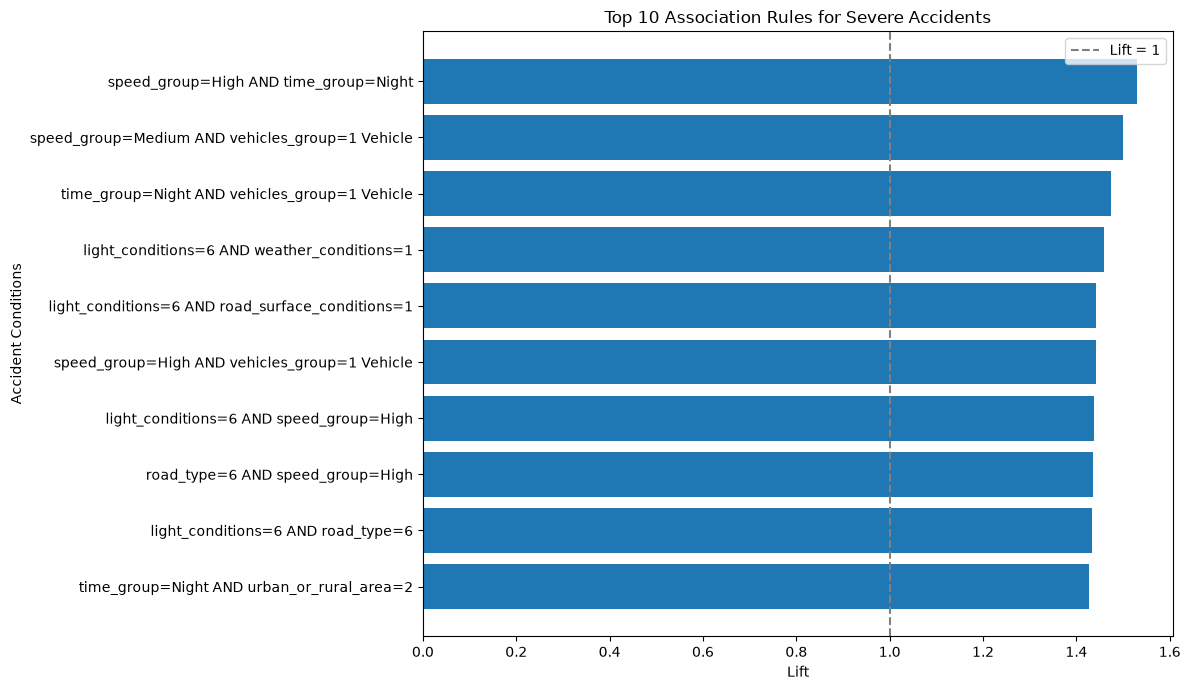

In [11]:

# STEP 16: Visualize Top Rules

import matplotlib.pyplot as plt

if top_rules.empty:
    print("No positive Severe rules found.")
else:
    plot_data = top_rules.sort_values("lift")

    plt.figure(figsize=(12, 7))

    plt.barh(
        plot_data["Conditions"],
        plot_data["lift"]
    )

    plt.axvline(
        x=1,
        color="gray",
        linestyle="--",
        label="Lift = 1"
    )

    plt.xlabel("Lift")
    plt.ylabel("Accident Conditions")
    plt.title("Top 10 Association Rules for Severe Accidents")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [12]:

# STEP 17: Evaluate Apriori Results

baseline = transactions["Severity=Severe"].mean()

print(f"Total accidents: {len(transactions):,}")
print(f"Baseline Severe Rate: {baseline:.2%}")
print(f"Minimum Support: {min_support}")
print(f"Frequent Itemsets: {len(frequent_itemsets)}")
print(f"Positive Severe Rules: {len(severe_rules)}")

if not top_rules.empty:
    print("\nStrongest Rule:")
    best = top_rules.iloc[0]

    print("Conditions:", best["Conditions"])
    print(f"Support: {best['support']:.2%}")
    print(f"Confidence: {best['confidence']:.2%}")
    print(f"Lift: {best['lift']:.3f}")

    print(
        "\nExpected severe accident count for this rule:",
        round(best["support"] * len(transactions))
    )


Total accidents: 101,525
Baseline Severe Rate: 26.24%
Minimum Support: 0.005
Frequent Itemsets: 1569
Positive Severe Rules: 114

Strongest Rule:
Conditions: speed_group=High AND time_group=Night
Support: 0.50%
Confidence: 40.16%
Lift: 1.530

Expected severe accident count for this rule: 508
